#### Prelimnary Analysis - Seaborn + plotly
<pre>
1) Check null values and duplicates in each df. Create Functions for the same
2) Find Count of Customers from each city and represent it on bar chart.
3) Find Range Age wise count of cutsomers, represent it on pie chart. 
4) Find Count of each activity, represent it on bar chart
5) Find order month wise total amount. Represent it on line chart.
6) Find Sub_Plan wise total revenue generated. Represent it on bar chart.
7) City wise find total amount
8) Find count of each payment mode, represent it on donut chart
9) Represent Payment mode wise sum of amount on a strip plot

</pre>
#### Objective - Funnel Analysis
<pre>
1) Generate the Entire Funnel. Represent 4 columns
- Funnel_Stage, Count_of_Cust, Percenatge_Conversion

2) Find Customer wise count of days to transition from one stage of funnel to the next stage

3) Find Avg_Days to transition from one Funnel stage to the next stage.

4) Create function to analyse Funnel based on City. 

</pre>


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
cb = pd.read_csv('cust_bio.csv')
sp = pd.read_csv('sp.csv')
ca = pd.read_csv('cust_activity.csv')
orders = pd.read_csv('orders (1).csv')
cs = pd.read_csv('cust_sub.csv')

In [4]:
print(cb.shape)
print(sp.shape)
print(ca.shape)
print(orders.shape)
print(cs.shape)

(478, 3)
(6, 5)
(7500, 3)
(127, 4)
(51, 3)


In [5]:
print(cb.columns)
print(ca.columns)
print(orders.columns)
print(sp.columns)
print(cs.columns)

Index(['Cust_ID', 'City', 'Age'], dtype='str')
Index(['Cust_ID', 'Activity', 'Date'], dtype='str')
Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')
Index(['Plan_Var_ID', 'Plan_ID', 'Plan_name', 'Price', 'Duration'], dtype='str')
Index(['Cust_ID', 'Plan_Var_ID', 'Purchase_Date'], dtype='str')


## Q) 1

In [6]:
def check_null_dup(data):
    dup = data.duplicated().sum()
    nv = data.isnull().sum()
    if dup == 0 and nv.sum()==0:
        print('no dupliacates and no null values')
    else:
        return dup,nv


In [7]:
check_null_dup(cb)
check_null_dup(ca)
check_null_dup(cs)
check_null_dup(sp)
check_null_dup(orders)

no dupliacates and no null values
no dupliacates and no null values
no dupliacates and no null values
no dupliacates and no null values
no dupliacates and no null values


## Q) 2

In [13]:
import plotly.express as px

In [12]:
c = cb['City'].value_counts().reset_index()
c

,City,count
0,Chennai,109
1,Delhi,106
2,Kolkata,94
3,Noida,92
4,Mumbai,77


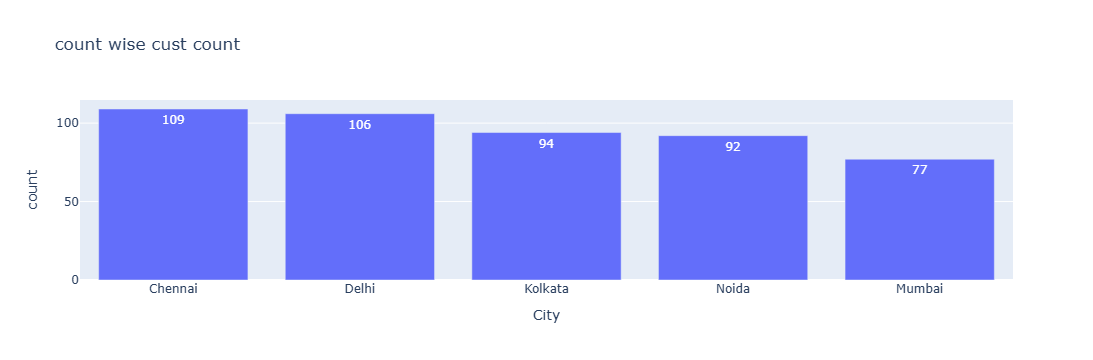

In [15]:
fig = px.bar(data_frame = c,x = 'City',y ='count',text = 'count',
             title = 'count wise cust count')
fig.show()

## Q) 3

In [19]:
cb['age_range'] = pd.cut(cb['Age'],bins = [19,23,27,31,35,39])
cb['age_range'] = cb['age_range'].astype(str)

In [21]:
a= cb['age_range'].value_counts().reset_index()
a

,age_range,count
0,"(31, 35]",116
1,"(19, 23]",112
2,"(23, 27]",95
3,"(27, 31]",93
4,"(35, 39]",62


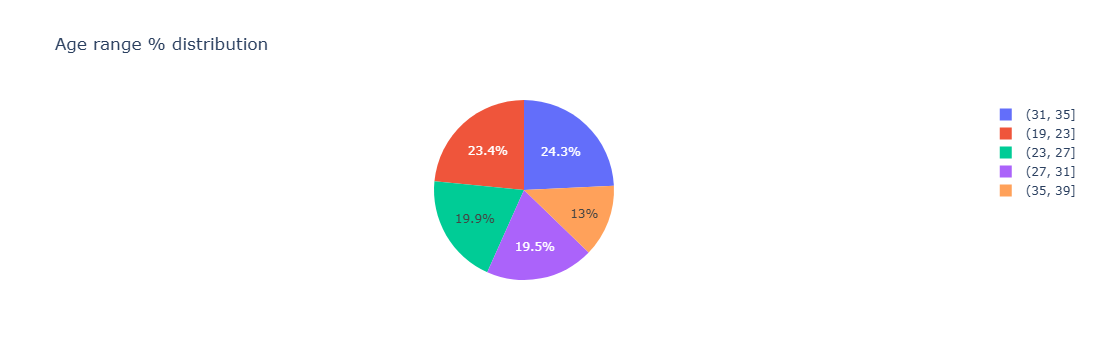

In [26]:
fig = px.pie(data_frame= a, names ='age_range',values ='count',title = 'Age range % distribution')
fig.show()

## Q 4

In [27]:
b = ca['Activity'].value_counts().reset_index()
b

,Activity,count
0,Browse,6548
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


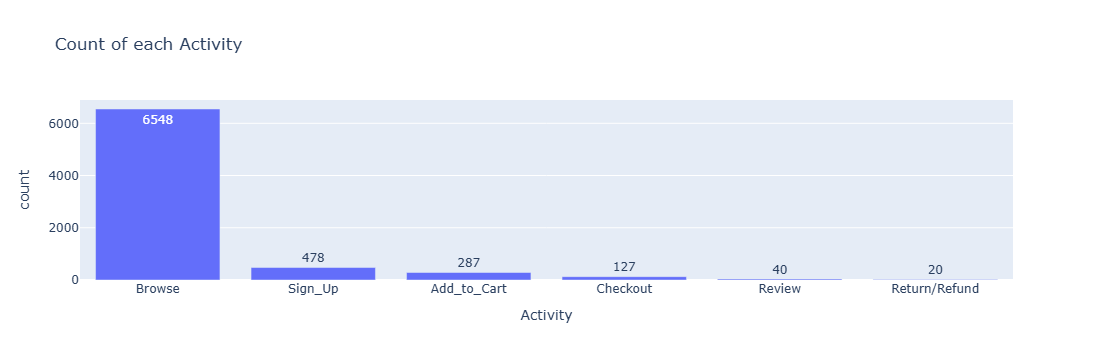

In [29]:
fig = px.bar(data_frame = b,x='Activity',y='count',text = 'count',title ='Count of each Activity')
fig.show()

## Q) 5

In [31]:
ca['Date'] = pd.to_datetime(ca['Date'])

In [35]:
ca_cout = ca[ca['Activity'] =='Checkout']
ca_cout.shape

(127, 3)

In [36]:
d = pd.merge(orders,ca_cout,on ='Cust_ID')
d['order_month']= d['Date'].dt.month
d.head(3)

,Order_id,Cust_ID,Amount,Payment_mode,Activity,Date,order_month
0,ORD_71,CUS_545,2123.19,UPI,Checkout,2024-04-26,4
1,ORD_72,CUS_622,2788.02,Net Banking,Checkout,2024-02-01,2
2,ORD_73,CUS_418,3071.63,Credit_Card,Checkout,2024-07-22,7


In [37]:
d_ans = d.groupby('order_month')['Amount'].sum().reset_index()
d_ans

,order_month,Amount
0,1,27022.20
1,2,70477.42
2,3,74777.59
3,4,88080.66
4,5,60200.46
5,6,69580.07
6,7,80416.05
7,8,27227.29
8,9,34804.62
9,10,30298.38


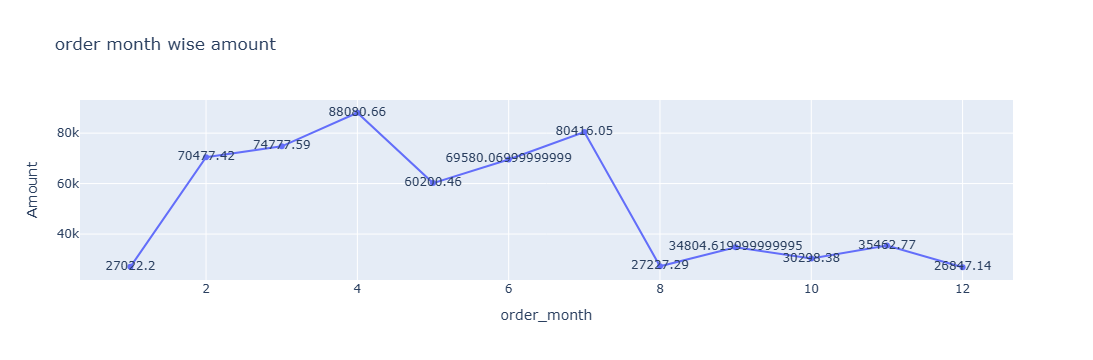

In [39]:
fig = px.line(data_frame=d_ans,x = 'order_month',y='Amount', text ='Amount',title ='order month wise amount')
fig.show()

## Q 6

In [41]:
cs_sp = pd.merge(cs,sp,on='Plan_Var_ID')
cs_sp.head()

,Cust_ID,Plan_Var_ID,Purchase_Date,Plan_ID,Plan_name,Price,Duration
0,CUS_626,P1_1Y,2025-05-15,P1,Silver,1200.0,1 Year
1,CUS_723,P1_1Y,2024-07-23,P1,Silver,1200.0,1 Year
2,CUS_575,P1_1Y,2024-11-14,P1,Silver,1200.0,1 Year
3,CUS_232,P2_6M,2025-04-19,P2,Gold,1440.0,6 Months
4,CUS_346,P2_1Y,2024-01-31,P2,Gold,2400.0,1 Year


In [42]:
d= cs_cp.groupby('Plan_Var_ID')['Price'].sum().reset_index()
d

,Plan_Var_ID,Price
0,P1_1Y,16800.0
1,P1_6M,5040.0
2,P2_1Y,24000.0
3,P2_6M,7200.0
4,P3_1Y,28800.0
5,P3_6M,25920.0


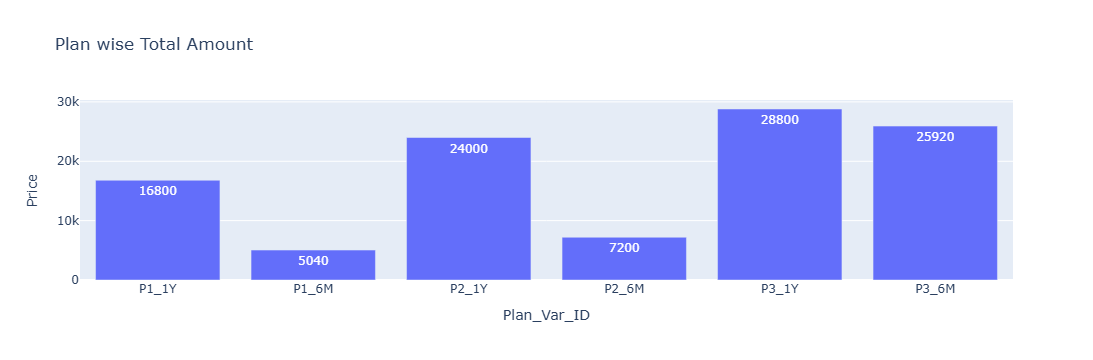

In [43]:
fig = px.bar(data_frame = d, x='Plan_Var_ID',y='Price',text='Price',title = 'Plan wise Total Amount')
fig.show()

## Q 7

In [46]:
cb.columns
orders.columns

Index(['Order_id', 'Cust_ID', 'Amount', 'Payment_mode'], dtype='str')

In [49]:
cb_od= pd.merge(cb,orders,on='Cust_ID')
cb_od.head()

,Cust_ID,City,Age,age_range,Order_id,Amount,Payment_mode
0,CUS_121,Noida,30,"(27, 31]",ORD_83,3336.69,UPI
1,CUS_127,Delhi,24,"(23, 27]",ORD_172,6427.90,Credit_Card
2,CUS_129,Mumbai,20,"(19, 23]",ORD_97,8653.62,UPI
3,CUS_135,Kolkata,35,"(31, 35]",ORD_87,2551.37,Credit_Card
4,CUS_139,Noida,34,"(31, 35]",ORD_127,3290.14,UPI


In [50]:
d= cb_od.groupby('City')['Amount'].sum().reset_index()
d

,City,Amount
0,Chennai,96763.72
1,Delhi,147176.17
2,Kolkata,102185.83
3,Mumbai,120515.98
4,Noida,158552.95


## Q 8

In [51]:
b = orders['Payment_mode'].value_counts().reset_index()
b

,Payment_mode,count
0,Net Banking,29
1,Debit Card,27
2,UPI,24
3,Credit_Card,24
4,COD,23


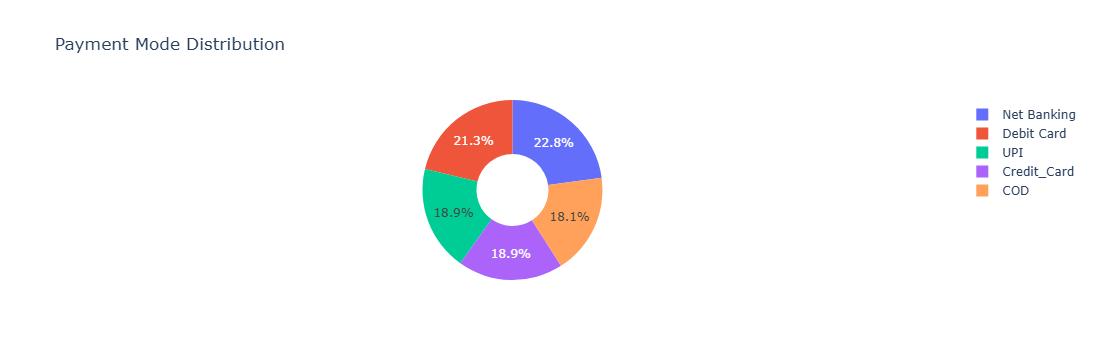

In [53]:
fig = px.pie(data_frame=b,names ='Payment_mode',values = 'count',hole =0.4,title = 'Payment Mode Distribution')
fig.show()

## Q) 9

In [55]:
a = orders.groupby('Payment_mode')['Amount'].sum().reset_index()
a

,Payment_mode,Amount
0,COD,115972.27
1,Credit_Card,127611.89
2,Debit Card,133145.11
3,Net Banking,137780.34
4,UPI,110685.04


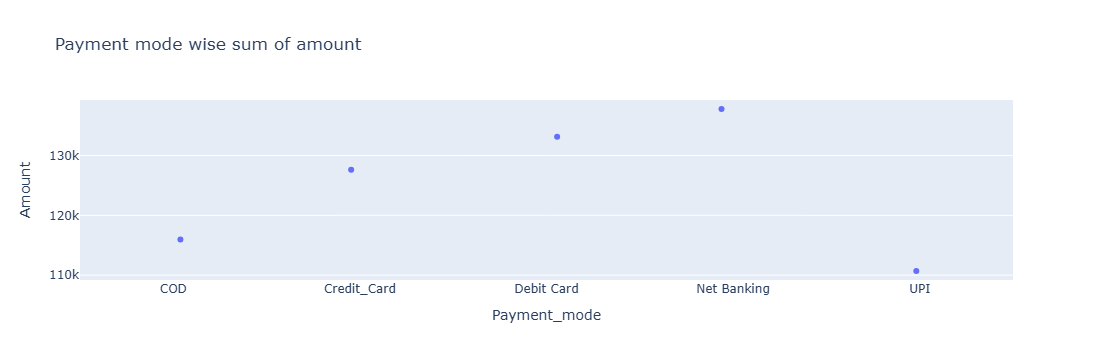

In [58]:
fig = px.strip(data_frame = a,x='Payment_mode',y='Amount',title = ' Payment mode wise sum of amount ')
fig.show()

## Funnel Analysis

In [60]:
z1 = ca.groupby(['Cust_ID','Activity'])['Activity'].count().reset_index(name ='count')
z1

,Cust_ID,Activity,count
0,CUS_121,Add_to_Cart,1
1,CUS_121,Browse,8
2,CUS_121,Checkout,1
3,CUS_121,Sign_Up,1
4,CUS_122,Browse,10
...,...,...,...
1628,CUS_798,Browse,10
1629,CUS_798,Sign_Up,1
1630,CUS_799,Browse,10
1631,CUS_800,Browse,12


In [74]:
funnel =z1['Activity'].value_counts().reset_index()
funnel

,Activity,count
0,Browse,681
1,Sign_Up,478
2,Add_to_Cart,287
3,Checkout,127
4,Review,40
5,Return/Refund,20


In [78]:
funnel['prev_count']=np.where(funnel['Activity']=='Return/Refund',funnel['count'].shift(2),funnel['count'].shift(1))
funnel

,Activity,count,prev_count
0,Browse,681,NaN
1,Sign_Up,478,681.0
2,Add_to_Cart,287,478.0
3,Checkout,127,287.0
4,Review,40,127.0
5,Return/Refund,20,127.0


In [79]:
funnel['Conversion%'] = round((funnel['count']/funnel['prev_count'])*100,2)
funnel = funnel.fillna(0)
funnel

,Activity,count,prev_count,Conversion%
0,Browse,681,0.0,0.00
1,Sign_Up,478,681.0,70.19
2,Add_to_Cart,287,478.0,60.04
3,Checkout,127,287.0,44.25
4,Review,40,127.0,31.50
5,Return/Refund,20,127.0,15.75


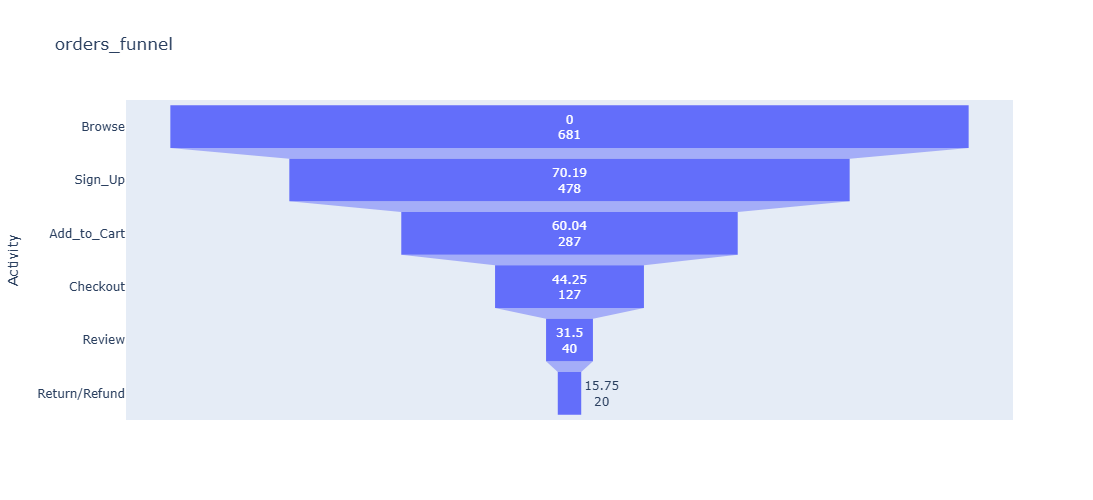

In [80]:
fig = px.funnel(data_frame=funnel,y='Activity',x='count',text='Conversion%',hover_data='count',title='orders_funnel',height=500)
fig.show()

## Q)2

In [81]:
pt1 = pd.pivot_table(data=ca,index='Cust_ID',columns='Activity',values = 'Date',aggfunc='min')
pt1.head(10)

Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up
Cust_ID,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21


In [83]:
pt1['dd_signup_2browse']=abs((pt1['Browse']-pt1['Sign_Up']).dt.days)
pt1['dd_add2cart_2browse']=(pt1['Add_to_Cart']-pt1['Browse']).dt.days
pt1['dd_checkout_2add2cart']=(pt1['Checkout']-pt1['Add_to_Cart']).dt.days
pt1['dd_review_2checkout']=(pt1['Review']-pt1['Checkout']).dt.days
pt1['dd_retrun/refund_2checkout']=(pt1['Checkout']-pt1['Add_to_Cart']).dt.days
pt1.head(10)






Activity,Add_to_Cart,Browse,Checkout,Return/Refund,Review,Sign_Up,dd_signup_2browse,dd_add2cart_2browse,dd_checkout_2add2cart,dd_review_2checkout,dd_retrun/refund_2checkout
Cust_ID,,,,,,,,,,,
CUS_121,2024-04-27,2024-04-27,2024-05-05,NaT,NaT,2024-04-24,3.0,0.0,8.0,NaN,8.0
CUS_122,NaT,2025-07-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_123,NaT,2024-04-14,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_124,2025-01-06,2025-01-06,NaT,NaT,NaT,2025-01-05,1.0,0.0,NaN,NaN,NaN
CUS_125,NaT,2024-06-17,NaT,NaT,NaT,2024-06-15,2.0,NaN,NaN,NaN,NaN
CUS_126,NaT,2024-02-28,NaT,NaT,NaT,2024-02-27,1.0,NaN,NaN,NaN,NaN
CUS_127,2024-05-28,2024-05-28,2024-06-16,NaT,NaT,2024-05-26,2.0,0.0,19.0,NaN,19.0
CUS_128,NaT,2024-06-12,NaT,NaT,NaT,NaT,NaN,NaN,NaN,NaN,NaN
CUS_129,2025-03-22,2025-03-22,2025-04-02,NaT,NaT,2025-03-21,1.0,0.0,11.0,NaN,11.0


In [84]:
pt2 = pt1.iloc[:,-5:]
pt2.head()

Activity,dd_signup_2browse,dd_add2cart_2browse,dd_checkout_2add2cart,dd_review_2checkout,dd_retrun/refund_2checkout
Cust_ID,,,,,
CUS_121,3.0,0.0,8.0,NaN,8.0
CUS_122,NaN,NaN,NaN,NaN,NaN
CUS_123,NaN,NaN,NaN,NaN,NaN
CUS_124,1.0,0.0,NaN,NaN,NaN
CUS_125,2.0,NaN,NaN,NaN,NaN


## Q)3

In [86]:
avg_dd = np.round( pt2.mean().values,2)
avg_dd

array([ 2.52,  0.86, 14.43,  2.62, 14.43])

In [87]:
avg_dd = [0]+ list(avg_dd)
avg_dd

[0,
 np.float64(2.52),
 np.float64(0.86),
 np.float64(14.43),
 np.float64(2.62),
 np.float64(14.43)]

In [89]:
funnel['Avg_daydidd']=avg_dd
funnel

,Activity,count,prev_count,Conversion%,Avg_daydidd
0,Browse,681,0.0,0.00,0.00
1,Sign_Up,478,681.0,70.19,2.52
2,Add_to_Cart,287,478.0,60.04,0.86
3,Checkout,127,287.0,44.25,14.43
4,Review,40,127.0,31.50,2.62
5,Return/Refund,20,127.0,15.75,14.43


In [92]:
funnel['Conversion%'] = funnel['Conversion%'].apply(lambda x : str(x) + '%')
funnel

,Activity,count,prev_count,Conversion%,Avg_daydidd
0,Browse,681,0.0,0.0%,0.00
1,Sign_Up,478,681.0,70.19%,2.52
2,Add_to_Cart,287,478.0,60.04%,0.86
3,Checkout,127,287.0,44.25%,14.43
4,Review,40,127.0,31.5%,2.62
5,Return/Refund,20,127.0,15.75%,14.43


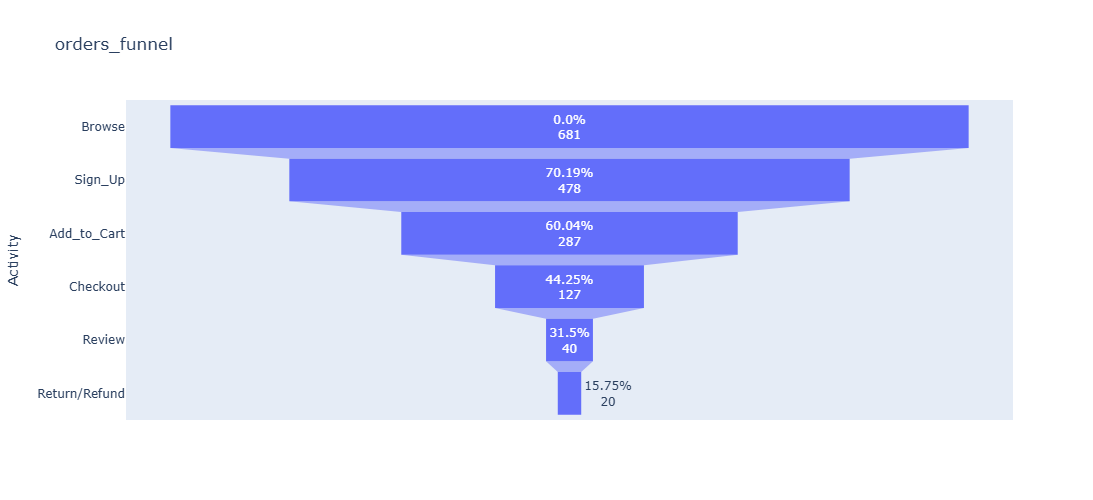

In [93]:
fig = px.funnel(data_frame=funnel,y='Activity',x='count',text='Conversion%',hover_data='count',title='orders_funnel',height=500)
fig.show()